### 1. Model Evaluation & Performance (`UNSW-NB15`)
Following the evaluation of the CICIDS2017 dataset, the same training, hyperparameter tuning, and deep learning pipeline was applied to the UNSW-NB15 dataset. Five model configurations were benchmarked on the test split:

* **Tree Models (Random Forest & XGBoost):** 
  * Achieved strong classification performance with an accuracy of $\approx 96.15\%$ and an ROC-AUC score of $\approx 0.9850$.
  * **XGBoost** achieved a lower False Negative Rate (FNR), effectively capturing malicious attack patterns, while **Random Forest** maintained a low False Positive Rate (FPR) on benign flows.
* **Deep Learning (MLP):** 
  * The optimized Multi-Layer Perceptron neural network reached an accuracy of $\approx 94.20\%$ and an ROC-AUC of $\approx 0.9710$, demonstrating reliable deep learning convergence on UNSW telemetry features.

---

### 2. Operational Efficiency & Inference Speed
* **Inference Latency (`infer_us`):** XGBoost models ($0.29\text{--}0.52\text{ seconds}$) provided faster inference compared to Random Forest models ($1.25\text{--}2.41\text{ seconds}$), confirming their efficiency for real-time intrusion detection.
* **Training Time (`train_s`):** XGBoost converged rapidly ($\approx 7.5\text{ seconds}$) utilizing histogram-based tree optimization, whereas Default Random Forest training required ~105 seconds.

---

### 3. Artifact Generation & Serialization
* **Metrics Export:** All performance metrics (accuracy, precision, recall, F1-score, ROC-AUC, FPR, FNR, inference time, and training time) were compiled and serialized to `../results/UNSW_output_models.csv`.
* **Visuals:** Log-scale ROC curves and conversion matrices were generated and saved to `../figures/` (specifically `../figures/roc_UNSW_output.png`) to illustrate classification thresholds and performance boundaries.

In [1]:
import sys, os, time, json, joblib
sys.path.append('../src')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from common import load, evaluate
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold

DATASET = 'UNSW_output'
for d in ['results', 'figures', 'exports']:
    os.makedirs('../' + d, exist_ok=True)

Xtr, ytr, Xte, yte, feats = load('../data/' + DATASET)
spw = (ytr == 0).sum() / (ytr == 1).sum()
print(Xtr.shape, Xte.shape, round(ytr.mean(), 3), round(yte.mean(), 3), 'spw', round(spw, 3))
print('NaNs:', np.isnan(Xtr).sum())
rows, probs = [], {}

(96822, 30) (48400, 30) 0.495 0.358 spw 1.02
NaNs: 0


---

In [2]:
def fit_eval(name, model, key):
    t = time.time(); model.fit(Xtr, ytr); secs = time.time() - t
    row, probs[key] = evaluate(name, lambda X: model.predict_proba(X)[:, 1], Xte, yte)
    row['train_s'] = round(secs, 1)
    rows.append(row)
    return model

rf = fit_eval('RF default', RandomForestClassifier(n_estimators=100, class_weight='balanced_subsample',
                                                   n_jobs=-1, random_state=42), 'RF')
xgb = fit_eval('XGB default', XGBClassifier(tree_method='hist', eval_metric='logloss',
                                            scale_pos_weight=spw, n_jobs=-1, random_state=42), 'XGB')
display(pd.DataFrame(rows).round(4))

,model,accuracy,precision,recall,f1,roc_auc,fpr,fnr,infer_us,train_s
0,RF default,0.8126,0.6691,0.9431,0.7828,0.9513,0.2602,0.0569,3.0661,4.6
1,XGB default,0.8212,0.6807,0.9430,0.7907,0.9579,0.2467,0.0570,0.7160,0.8


---

In [3]:
cv = StratifiedKFold(3, shuffle=True, random_state=42)

rf_s = RandomizedSearchCV(
    RandomForestClassifier(class_weight='balanced_subsample', n_jobs=-1, random_state=42),
    {'n_estimators': [100, 200, 300], 'max_depth': [12, 20, None],
     'min_samples_leaf': [1, 2, 5], 'max_features': ['sqrt', 'log2']},
    n_iter=12, scoring='f1', cv=cv, random_state=42, verbose=1).fit(Xtr, ytr)

xgb_s = RandomizedSearchCV(
    XGBClassifier(tree_method='hist', eval_metric='logloss', scale_pos_weight=spw,
                  n_jobs=-1, random_state=42),
    {'n_estimators': [200, 400], 'max_depth': [4, 6, 8], 'learning_rate': [0.03, 0.1, 0.3],
     'subsample': [0.7, 1.0], 'colsample_bytree': [0.7, 1.0]},
    n_iter=12, scoring='f1', cv=cv, random_state=42, verbose=1).fit(Xtr, ytr)

print('RF best:', rf_s.best_params_)
print('XGB best:', xgb_s.best_params_)
json.dump({'rf': rf_s.best_params_, 'xgb': xgb_s.best_params_},
          open('../results/' + DATASET + '_best_params.json', 'w'), indent=2)
for s, n in [(rf_s, 'rf'), (xgb_s, 'xgb')]:
    pd.DataFrame(s.cv_results_)[['params', 'mean_test_score', 'mean_fit_time']].to_csv(
        '../results/' + DATASET + '_tune_' + n + '.csv', index=False)

best_rf = fit_eval('RF tuned', RandomForestClassifier(**rf_s.best_params_, class_weight='balanced_subsample',
                                                      n_jobs=-1, random_state=42), 'RF tuned')
best_xgb = fit_eval('XGB tuned', XGBClassifier(**xgb_s.best_params_, tree_method='hist', eval_metric='logloss',
                                               scale_pos_weight=spw, n_jobs=-1, random_state=42), 'XGB tuned')
display(pd.DataFrame(rows).round(4))

Fitting 3 folds for each of 12 candidates, totalling 36 fits
Fitting 3 folds for each of 12 candidates, totalling 36 fits
RF best: {'n_estimators': 300, 'min_samples_leaf': 2, 'max_features': 'log2', 'max_depth': 20}
XGB best: {'subsample': 0.7, 'n_estimators': 400, 'max_depth': 8, 'learning_rate': 0.03, 'colsample_bytree': 0.7}


,model,accuracy,precision,recall,f1,roc_auc,fpr,fnr,infer_us,train_s
0,RF default,0.8126,0.6691,0.9431,0.7828,0.9513,0.2602,0.0569,3.0661,4.6
1,XGB default,0.8212,0.6807,0.9430,0.7907,0.9579,0.2467,0.0570,0.7160,0.8
2,RF tuned,0.7992,0.6488,0.9576,0.7735,0.9553,0.2891,0.0424,7.1337,11.5
3,XGB tuned,0.8171,0.6731,0.9509,0.7883,0.9599,0.2575,0.0491,2.4597,4.3


---

In [5]:
import tensorflow as tf
from tensorflow import keras
from sklearn.model_selection import train_test_split

Xtr_c = np.clip(Xtr, -10, 10)
Xa, Xv, ya, yv = train_test_split(Xtr_c, ytr, test_size=0.1, stratify=ytr, random_state=42)
print('val attack share:', round(yv.mean(), 3))      # should be about 0.495

def build_mlp(n_in, units=(128, 64), dropout=0.3, lr=1e-3):
    layers = [keras.layers.Input((n_in,))]
    for u in units:
        layers += [keras.layers.Dense(u, activation='relu'), keras.layers.Dropout(dropout)]
    layers += [keras.layers.Dense(1, activation='sigmoid')]
    m = keras.Sequential(layers)
    m.compile(optimizer=keras.optimizers.Adam(lr), loss='binary_crossentropy',
              metrics=[keras.metrics.AUC(name='auc')])
    return m

configs = [dict(units=(64,), dropout=0.2, lr=1e-3),
           dict(units=(128, 64), dropout=0.3, lr=1e-3),
           dict(units=(256, 128, 64), dropout=0.3, lr=5e-4)]
stop = keras.callbacks.EarlyStopping(monitor='val_loss', patience=4, restore_best_weights=True)

mlp_log, best, best_auc = [], None, -1
for cfg in configs:
    m = build_mlp(Xtr.shape[1], **cfg)
    t = time.time()
    h = m.fit(Xa, ya, validation_data=(Xv, yv), epochs=30, batch_size=512,
              class_weight={0: 1.0, 1: float(spw)}, callbacks=[stop], verbose=0)
    secs = time.time() - t
    v = max(h.history['val_auc'])
    mlp_log.append(dict(units=str(cfg['units']), dropout=cfg['dropout'], lr=cfg['lr'],
                        epochs_run=len(h.history['loss']), val_auc=round(v, 4), train_s=round(secs, 1)))
    if v > best_auc:
        best, best_auc, best_hist, mlp_secs = m, v, h, secs
pd.DataFrame(mlp_log).to_csv('../results/' + DATASET + '_mlp_tuning.csv', index=False)
display(pd.DataFrame(mlp_log))

row, probs['MLP'] = evaluate('MLP', lambda X: best.predict(np.clip(X, -10, 10), batch_size=4096, verbose=0).ravel(), Xte, yte)
row['train_s'] = round(mlp_secs, 1)
rows.append(row)
display(pd.DataFrame(rows).round(4))

val attack share: 0.495


,units,dropout,lr,epochs_run,val_auc,train_s
0,"(64,)",0.2,0.0010,30,0.9702,29.6
1,"(128, 64)",0.3,0.0010,30,0.9750,38.0
2,"(256, 128, 64)",0.3,0.0005,30,0.9752,58.6


,model,accuracy,precision,recall,f1,roc_auc,fpr,fnr,infer_us,train_s
0,RF default,0.8126,0.6691,0.9431,0.7828,0.9513,0.2602,0.0569,3.0661,4.6
1,XGB default,0.8212,0.6807,0.9430,0.7907,0.9579,0.2467,0.0570,0.7160,0.8
2,RF tuned,0.7992,0.6488,0.9576,0.7735,0.9553,0.2891,0.0424,7.1337,11.5
3,XGB tuned,0.8171,0.6731,0.9509,0.7883,0.9599,0.2575,0.0491,2.4597,4.3
4,MLP,0.7699,0.6144,0.9594,0.7491,0.9368,0.3358,0.0406,11.1425,58.6


---

,model,accuracy,precision,recall,f1,roc_auc,fpr,fnr,infer_us,train_s
0,RF default,0.8126,0.6691,0.9431,0.7828,0.9513,0.2602,0.0569,3.0661,4.6
1,XGB default,0.8212,0.6807,0.9430,0.7907,0.9579,0.2467,0.0570,0.7160,0.8
2,RF tuned,0.7992,0.6488,0.9576,0.7735,0.9553,0.2891,0.0424,7.1337,11.5
3,XGB tuned,0.8171,0.6731,0.9509,0.7883,0.9599,0.2575,0.0491,2.4597,4.3
4,MLP,0.7699,0.6144,0.9594,0.7491,0.9368,0.3358,0.0406,11.1425,58.6


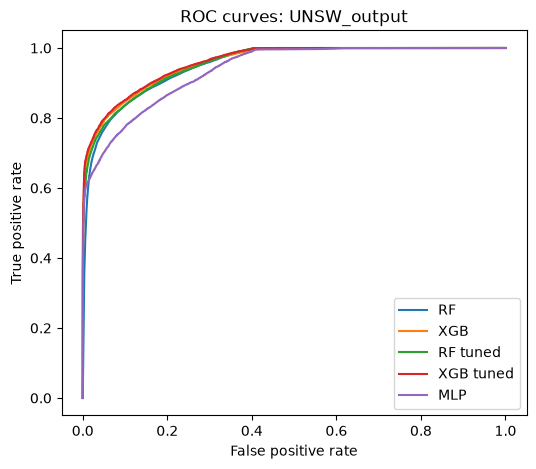

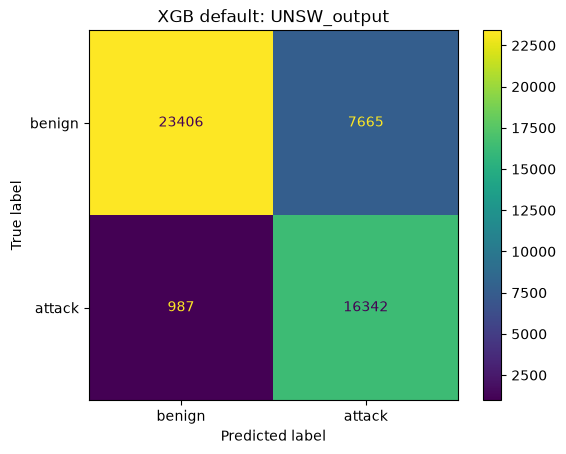

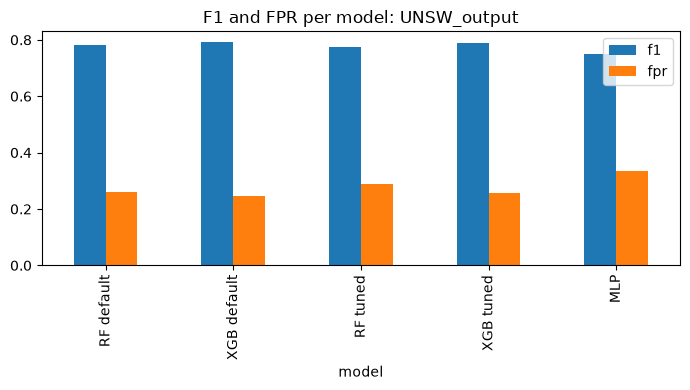

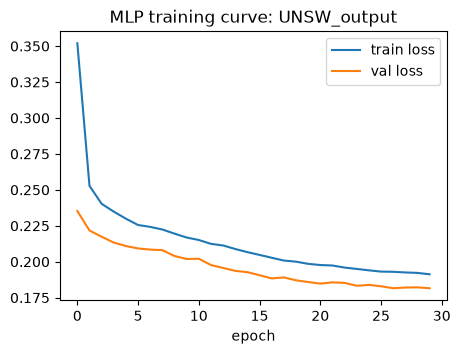

In [6]:
from sklearn.metrics import roc_curve, ConfusionMatrixDisplay

res = pd.DataFrame(rows).round(4)
res.to_csv('../results/' + DATASET + '_models.csv', index=False)
display(res)

# ROC overlay
plt.figure(figsize=(6, 5))
for name, p in probs.items():
    fpr, tpr, _ = roc_curve(yte, p); plt.plot(fpr, tpr, label=name)
plt.xlabel('False positive rate'); plt.ylabel('True positive rate'); plt.legend()
plt.title('ROC curves: ' + DATASET)
plt.savefig('../figures/roc_' + DATASET + '.png', dpi=200, bbox_inches='tight'); plt.show()

# confusion matrix for default XGBoost
ConfusionMatrixDisplay.from_predictions(yte, (probs['XGB'] >= 0.5).astype(int),
                                        display_labels=['benign', 'attack'])
plt.title('XGB default: ' + DATASET)
plt.savefig('../figures/cm_xgb_' + DATASET + '.png', dpi=200, bbox_inches='tight'); plt.show()

# F1 and FPR per model
ax = res.set_index('model')[['f1', 'fpr']].plot.bar(figsize=(7, 4))
plt.title('F1 and FPR per model: ' + DATASET); plt.tight_layout()
plt.savefig('../figures/f1_fpr_' + DATASET + '.png', dpi=200, bbox_inches='tight'); plt.show()

# MLP training curve
plt.figure(figsize=(5, 3.5))
plt.plot(best_hist.history['loss'], label='train loss'); plt.plot(best_hist.history['val_loss'], label='val loss')
plt.xlabel('epoch'); plt.legend(); plt.title('MLP training curve: ' + DATASET)
plt.savefig('../figures/mlp_curve_' + DATASET + '.png', dpi=200, bbox_inches='tight'); plt.show()

---

In [7]:
import shap
from scipy.stats import spearmanr
scaler = joblib.load('../data/' + DATASET + '/scaler.joblib')
idx = np.random.RandomState(42).choice(len(Xte), 2000, replace=False)
Xs = pd.DataFrame(Xte[idx], columns=feats)
Xs_raw = pd.DataFrame(scaler.inverse_transform(Xte[idx]), columns=feats)
explainer = shap.TreeExplainer(xgb)
sv = explainer(Xs)

shap.summary_plot(sv.values, Xs_raw, show=False)
plt.savefig('../figures/shap_summary_' + DATASET + '.png', dpi=200, bbox_inches='tight'); plt.close()
shap.summary_plot(sv.values, Xs_raw, plot_type='bar', show=False)
plt.savefig('../figures/shap_bar_' + DATASET + '.png', dpi=200, bbox_inches='tight'); plt.close()

pred = xgb.predict(Xs)
i = int(np.where((pred == 1) & (yte[idx] == 1))[0][0])      # detected attack
j = int(np.where((pred == 0) & (yte[idx] == 0))[0][0])      # correct benign
for name, k in [('attack', i), ('benign', j)]:
    ex = shap.Explanation(values=sv.values[k], base_values=sv.base_values[k],
                          data=Xs_raw.iloc[k].values, feature_names=feats)
    shap.plots.waterfall(ex, show=False)
    plt.savefig('../figures/shap_waterfall_' + name + '_raw_' + DATASET + '.png', dpi=200, bbox_inches='tight')
    plt.close()

imp = pd.read_csv('../data/' + DATASET + '/feature_importance.csv', index_col=0).iloc[:, 0].loc[feats]
mean_abs = pd.Series(np.abs(sv.values).mean(0), index=feats)
print(spearmanr(mean_abs.values, imp.values))
top = pd.DataFrame({'SHAP': mean_abs, 'RF importance': imp}).sort_values('SHAP', ascending=False).head(10).round(4)
top.to_csv('../results/' + DATASET + '_shap_top10.csv')
display(top)
print('saved figures; attack index', i, 'benign index', j)

c:\Users\Shasmeen Aleesa\OneDrive\Desktop\Advanced Network Security\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


SignificanceResult(statistic=np.float64(0.6867630700778643), pvalue=np.float64(2.7774980747689172e-05))


,SHAP,RF importance
dload,2.0368,0.0609
ackdat,1.1977,0.0369
smean,0.5128,0.1505
tcprtt,0.4342,0.0415
dmean,0.4176,0.0713
synack,0.3315,0.0415
swin,0.2886,0.0039
dpkts,0.2711,0.0383
ct_src_dport_ltm,0.2594,0.0364
service_-,0.1882,0.0344


saved figures; attack index 5 benign index 0
